fraction of coefficients left undivided: 0.9960785209551657


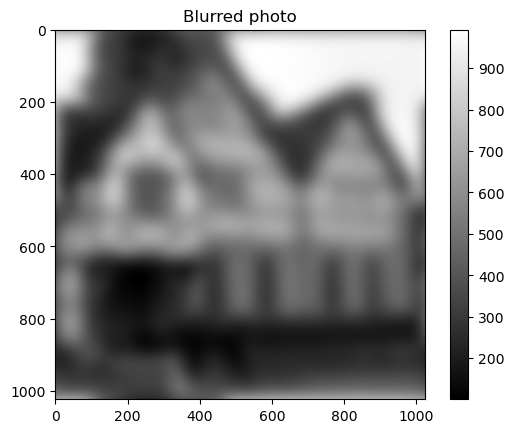

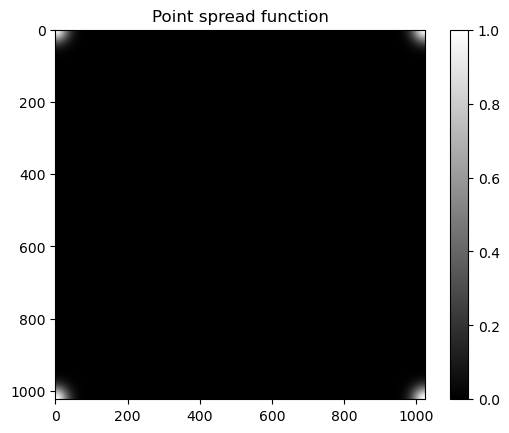

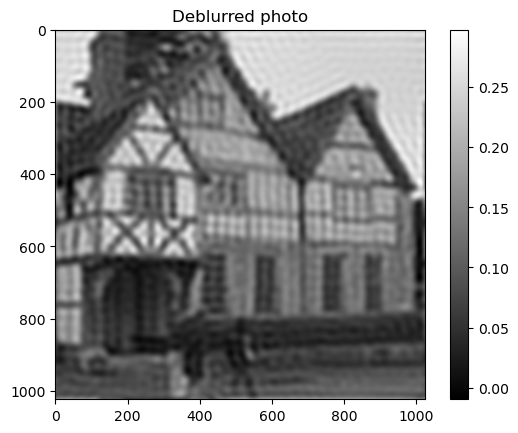

In [2]:
import numpy as np
import matplotlib.pyplot as plt

sigma = 25.0
eps = 1e-3

# (a) Blurred photo
blur = np.loadtxt("/Users/nichaeadnan/Desktop/blur.txt")
K, L = blur.shape

plt.figure()
plt.imshow(blur, cmap="gray")
plt.title("Blurred photo")
plt.colorbar()
plt.savefig("/Users/nichaeadnan/Desktop/blurred.png", dpi=150)

# (b) Gaussian point spread function
x = np.arange(L)
x = np.where(x <= L // 2, x, x - L)      #negative x values wrap around to the end
y = np.arange(K)
y = np.where(y <= K // 2, y, y - K)
X, Y = np.meshgrid(x, y)
f = np.exp(-(X**2 + Y**2) / (2 * sigma**2))

plt.figure()
plt.imshow(f, cmap="gray")
plt.title("Point spread function")
plt.colorbar()
plt.savefig("/Users/nichaeadnan/Desktop/psf.png", dpi=150)

# (c) Deconvolution
b_hat = np.fft.rfft2(blur)               #i, ii, iii: transform photo
f_hat = np.fft.rfft2(f)

a_hat = b_hat.copy()
mask = np.abs(f_hat) > eps               #only divide where f_hat is not small
a_hat[mask] = b_hat[mask] / f_hat[mask]  #iv: divide

a = np.fft.irfft2(a_hat, s=blur.shape)   #v: inverse transform

plt.figure()
plt.imshow(a, cmap="gray")               #vi: display
plt.title("Deblurred photo")
plt.colorbar()
plt.savefig("/Users/nichaeadnan/Desktop/deblurred.png", dpi=150)

print("fraction of coefficients left undivided:", 1 - mask.mean())
plt.show()